# Student Dropout Prediction - ML Zoomcamp Midterm

Predicting whether a student will drop out of higher education based on academic performance, demographic background, and financial indicators.

- **Dataset:** Predict Students' Dropout and Academic Success (UCI)
- **Target:** `Dropout` = 1, `Graduate` / `Enrolled` = 0

In [1]:
import pickle
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

## 1. Data Loading & Preparation

In [2]:
# Data uses semicolon delimiter
df = pd.read_csv('data.csv', sep=';')

# Clean column names to snake_case
df.columns = (
    df.columns.str.lower()
    .str.strip()
    .str.replace(' ', '_')
    .str.replace('(', '', regex=False)
    .str.replace(')', '', regex=False)
    .str.replace('/', '_', regex=False)
    .str.replace("'", '', regex=False)
)

print(f"Shape: {df.shape}")
print(f"Missing values: {df.isnull().sum().sum()}")
df.head(3)

Shape: (4424, 37)
Missing values: 0


,marital_status,application_mode,application_order,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nacionality,mothers_qualification,fathers_qualification,...,curricular_units_2nd_sem_credited,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_evaluations,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,curricular_units_2nd_sem_without_evaluations,unemployment_rate,inflation_rate,gdp,target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout


## 2. Target Variable

In the original dataset, students are marked as `Graduate`, `Dropout`, or `Enrolled`. For an early warning system, we want to flag students at risk of dropping out (`1`), while students who graduate or are continuing their studies are `0`.

In [3]:
print("Original target counts:")
print(df['target'].value_counts())

df['target'] = df['target'].map({'Dropout': 1, 'Graduate': 0, 'Enrolled': 0})

dropout_rate = df['target'].mean()
print(f"\nBinary target - Dropout rate: {dropout_rate:.3f} ({dropout_rate*100:.1f}%)")

Original target counts:
target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Binary target - Dropout rate: 0.321 (32.1%)


## 3. Exploratory Data Analysis & Feature Importance

Let's check summary statistics and explore which features relate most strongly to dropout.

In [4]:
# Summary statistics for numerical variables
df.describe().T[['mean', 'std', 'min', '50%', 'max']].round(2)

,mean,std,min,50%,max
marital_status,1.18,0.61,1.00,1.00,6.00
application_mode,18.67,17.48,1.00,17.00,57.00
application_order,1.73,1.31,0.00,1.00,9.00
course,8856.64,2063.57,33.00,9238.00,9991.00
daytime_evening_attendance,0.89,0.31,0.00,1.00,1.00
previous_qualification,4.58,10.22,1.00,1.00,43.00
previous_qualification_grade,132.61,13.19,95.00,133.10,190.00
nacionality,1.87,6.91,1.00,1.00,109.00
mothers_qualification,19.56,15.60,1.00,19.00,44.00
fathers_qualification,22.28,15.34,1.00,19.00,44.00


Checking key financial factors (`tuition_fees_up_to_date`, `debtor`, `scholarship_holder`):

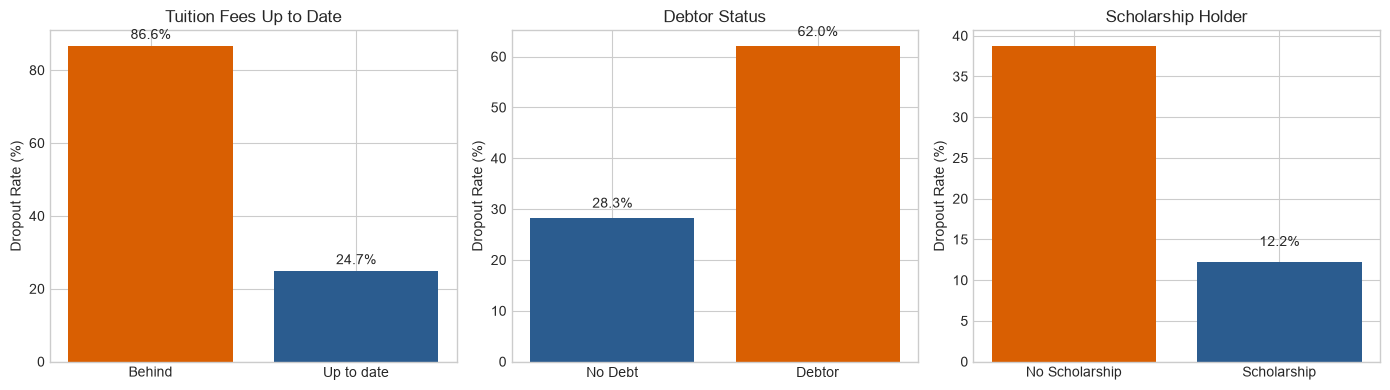

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Tuition fees status
tuition_rate = df.groupby('tuition_fees_up_to_date')['target'].mean() * 100
axes[0].bar(['Behind', 'Up to date'], tuition_rate, color=['#d95f02', '#2b5c8f'])
axes[0].set_ylabel('Dropout Rate (%)')
axes[0].set_title('Tuition Fees Up to Date')
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width()/2., p.get_height() + 2), ha='center')

# Debtor status
debtor_rate = df.groupby('debtor')['target'].mean() * 100
axes[1].bar(['No Debt', 'Debtor'], debtor_rate, color=['#2b5c8f', '#d95f02'])
axes[1].set_ylabel('Dropout Rate (%)')
axes[1].set_title('Debtor Status')
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width()/2., p.get_height() + 2), ha='center')

# Scholarship holder
scholar_rate = df.groupby('scholarship_holder')['target'].mean() * 100
axes[2].bar(['No Scholarship', 'Scholarship'], scholar_rate, color=['#d95f02', '#2b5c8f'])
axes[2].set_ylabel('Dropout Rate (%)')
axes[2].set_title('Scholarship Holder')
for p in axes[2].patches:
    axes[2].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width()/2., p.get_height() + 2), ha='center')

plt.tight_layout()
plt.show()

Tuition payment status is a huge signal: students behind on tuition drop out 86.6% of the time, vs 24.7% for those current.

Now let's check academic performance (units approved and grades in the 2nd semester):

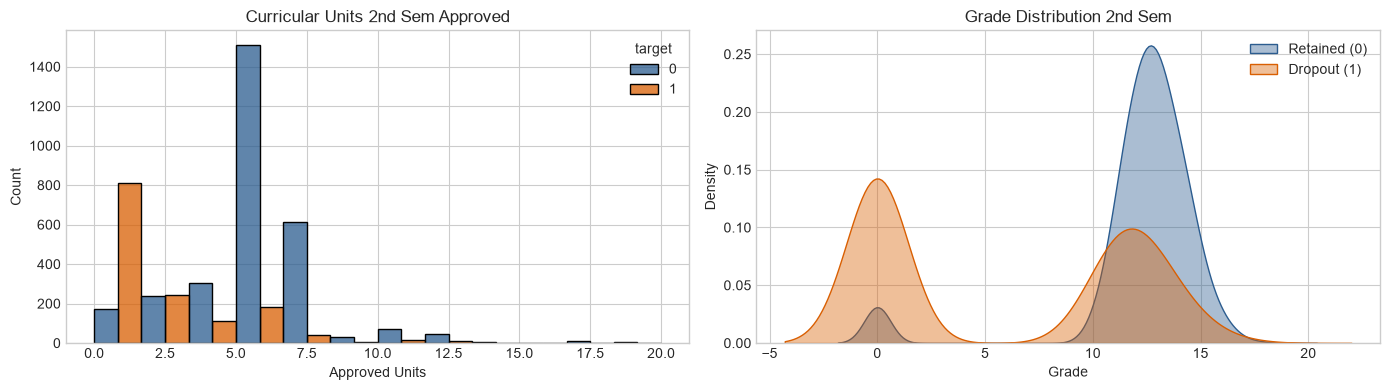

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Units approved 2nd semester
sns.histplot(data=df, x='curricular_units_2nd_sem_approved', hue='target', multiple='dodge', bins=12, ax=axes[0], palette=['#2b5c8f', '#d95f02'])
axes[0].set_title('Curricular Units 2nd Sem Approved')
axes[0].set_xlabel('Approved Units')

# Grades 2nd semester
sns.kdeplot(data=df[df['target']==0]['curricular_units_2nd_sem_grade'], ax=axes[1], label='Retained (0)', fill=True, color='#2b5c8f', alpha=0.4)
sns.kdeplot(data=df[df['target']==1]['curricular_units_2nd_sem_grade'], ax=axes[1], label='Dropout (1)', fill=True, color='#d95f02', alpha=0.4)
axes[1].set_title('Grade Distribution 2nd Sem')
axes[1].set_xlabel('Grade')
axes[1].legend()

plt.tight_layout()
plt.show()

Now let's compute Pearson correlation and Mutual Information across all features to see the top predictors:

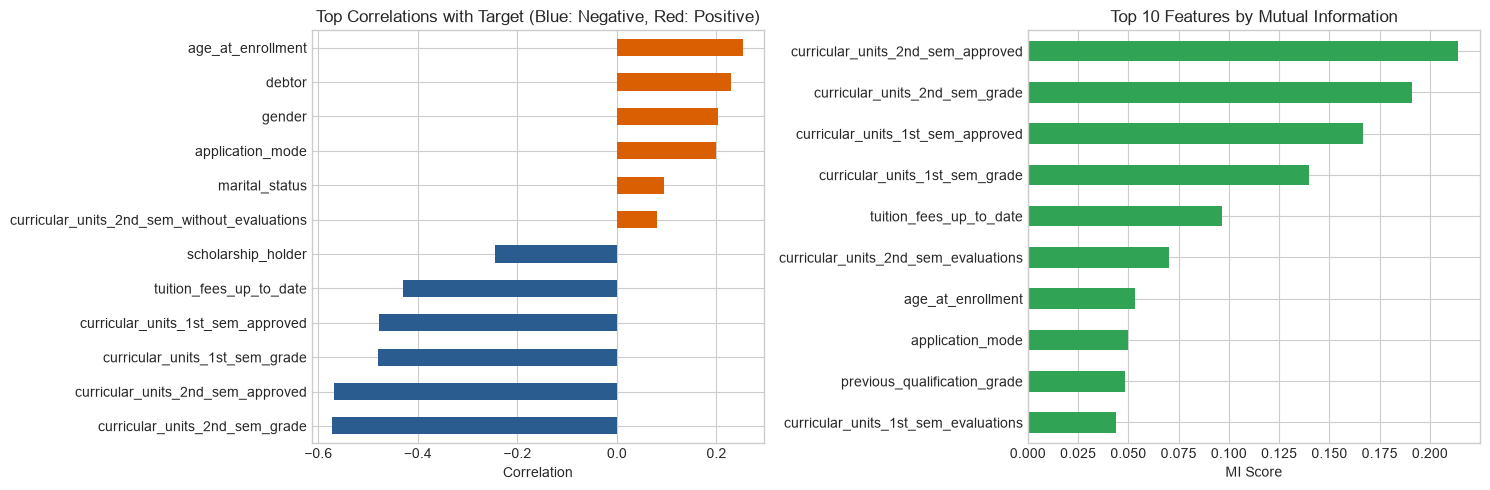

In [7]:
from sklearn.feature_selection import mutual_info_classif

# Correlation with target
corrs = df.corr()['target'].drop('target').sort_values()

# Mutual information
X_raw = df.drop(columns=['target'])
mi = mutual_info_classif(X_raw, df['target'], random_state=42)
mi_series = pd.Series(mi, index=X_raw.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Top correlations
top_corrs = pd.concat([corrs.head(6), corrs.tail(6)])
colors = ['#2b5c8f' if x < 0 else '#d95f02' for x in top_corrs.values]
top_corrs.plot(kind='barh', ax=axes[0], color=colors)
axes[0].set_title('Top Correlations with Target (Blue: Negative, Red: Positive)')
axes[0].set_xlabel('Correlation')

# Top mutual info
mi_series.head(10).sort_values().plot(kind='barh', ax=axes[1], color='#31a354')
axes[1].set_title('Top 10 Features by Mutual Information')
axes[1].set_xlabel('MI Score')

plt.tight_layout()
plt.show()

## 4. Train, Validation & Test Split

We split the data: 60% train, 20% validation, 20% test. We stratify on `target` to preserve the 32% dropout proportion across all sets.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer

# Split 80% full_train, 20% test
full_train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['target'])

# Split full_train into 60% train and 20% val
train_df, val_df = train_test_split(full_train_df, test_size=0.25, random_state=42, stratify=full_train_df['target'])

y_train = train_df['target'].values
y_val = val_df['target'].values
y_test = test_df['target'].values

train_df = train_df.drop(columns=['target']).reset_index(drop=True)
val_df = val_df.drop(columns=['target']).reset_index(drop=True)
test_df = test_df.drop(columns=['target']).reset_index(drop=True)

# DictVectorizer for feature encoding
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_df.to_dict(orient='records'))
X_val = dv.transform(val_df.to_dict(orient='records'))
X_test = dv.transform(test_df.to_dict(orient='records'))

print(f"Train: {X_train.shape[0]} samples, Val: {X_val.shape[0]} samples, Test: {X_test.shape[0]} samples")
print(f"Features: {X_train.shape[1]}")

Train: 2654 samples, Val: 885 samples, Test: 885 samples
Features: 36


## 5. Model Training & Parameter Tuning

We will train and evaluate:
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. XGBoost

### 5.1 Logistic Regression
Tuning regularization parameter `C`:

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score

scores = []
for c in [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0]:
    lr = LogisticRegression(solver='liblinear', C=c, random_state=42, max_iter=1000)
    lr.fit(X_train, y_train)
    
    proba = lr.predict_proba(X_val)[:, 1]
    pred = (proba >= 0.5).astype(int)
    
    auc = roc_auc_score(y_val, proba)
    f1 = f1_score(y_val, pred)
    scores.append((c, auc, f1))
    
scores_df = pd.DataFrame(scores, columns=['C', 'auc', 'f1']).sort_values(by='auc', ascending=False)
scores_df.head(5)

,C,auc,f1
4,1.0,0.923818,0.793296
5,5.0,0.923637,0.797774
3,0.5,0.923414,0.796992
6,10.0,0.923080,0.798493
2,0.1,0.922852,0.790960


### 5.2 Decision Tree
Tuning `max_depth` and `min_samples_leaf` to avoid overfitting:

In [10]:
from sklearn.tree import DecisionTreeClassifier

scores = []
for d in [2, 4, 6, 8, None]:
    for leaf in [1, 5, 10, 20]:
        dt = DecisionTreeClassifier(max_depth=d, min_samples_leaf=leaf, random_state=42)
        dt.fit(X_train, y_train)
        
        proba = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, proba)
        scores.append((d, leaf, auc))

scores_df = pd.DataFrame(scores, columns=['max_depth', 'min_samples_leaf', 'auc']).sort_values(by='auc', ascending=False)
scores_df.head(5)

,max_depth,min_samples_leaf,auc
7,4.0,20,0.901285
6,4.0,10,0.896598
11,6.0,20,0.895957
15,8.0,20,0.893323
5,4.0,5,0.891645


### 5.3 Random Forest
Tuning `n_estimators` and `max_depth`:

In [11]:
from sklearn.ensemble import RandomForestClassifier

scores = []
for d in [2, 4, 6, 8, None]:
    for leaf in [1, 5, 10, 20]:
        for n in [25, 50, 100, 150, 200]:
            rf = RandomForestClassifier(n_estimators=n, max_depth=d, min_samples_leaf=leaf, random_state=42, n_jobs=-1)
            rf.fit(X_train, y_train)

            proba = rf.predict_proba(X_val)[:, 1]
            auc = roc_auc_score(y_val, proba)
            scores.append((d, leaf, n, auc))

scores_df = pd.DataFrame(scores, columns=['max_depth', 'min_samples_leaf', 'n_estimators', 'auc']).sort_values(by='auc', ascending=False)
scores_df.head(20)

,max_depth,min_samples_leaf,n_estimators,auc
88,NaN,5,150,0.923713
93,NaN,10,150,0.923531
87,NaN,5,100,0.923379
94,NaN,10,200,0.923227
63,8.0,1,150,0.923162
64,8.0,1,200,0.923086
89,NaN,5,200,0.922992
69,8.0,5,200,0.922453
91,NaN,10,50,0.922277
86,NaN,5,50,0.922242


### 5.4 XGBoost
Tuning `eta`, `max_depth`, and `min_child_weight`:

In [12]:
import xgboost as xgb

features = dv.get_feature_names_out().tolist()
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)
dtest = xgb.DMatrix(X_test, label=y_test, feature_names=features)

scores = []
for eta in [0.01, 0.05, 0.1, 0.15, 0.3, 0.5]:
    for d in [3, 4, 5, 6]:
        for mcw in [1, 2, 3, 5]:
            params = {
                'eta': eta,
                'max_depth': d,
                'min_child_weight': mcw,
                'objective': 'binary:logistic',
                'eval_metric': 'auc',
                'seed': 42
            }
            model = xgb.train(params, dtrain, num_boost_round=100, verbose_eval=False)
            proba = model.predict(dval)
            auc = roc_auc_score(y_val, proba)
            scores.append((eta, d, mcw, auc))

scores_df = pd.DataFrame(scores, columns=['eta', 'max_depth', 'min_child_weight', 'auc']).sort_values(by='auc', ascending=False)
scores_df.head(5)

,eta,max_depth,min_child_weight,auc
34,0.1,3,3,0.933157
33,0.1,3,2,0.932952
35,0.1,3,5,0.932800
32,0.1,3,1,0.931675
38,0.1,4,3,0.931446


## 6. Model Comparison & Selection

In [13]:
# Compare tuned models on validation set
models = {
    'Logistic Regression (C=1.0)': LogisticRegression(solver='liblinear', C=1.0, random_state=42, max_iter=1000).fit(X_train, y_train),
    'Decision Tree (d=4, leaf=20)': DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=42).fit(X_train, y_train),
    'Random Forest (n=200, d=8, leaf=5)': RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(X_train, y_train),
}

results = []
for name, m in models.items():
    proba = m.predict_proba(X_val)[:, 1]
    pred = (proba >= 0.5).astype(int)
    results.append({
        'Model': name,
        'Val AUC': roc_auc_score(y_val, proba),
        'Val F1': f1_score(y_val, pred),
    })

# Add best XGBoost
xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 3,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'seed': 42
}
best_xgb = xgb.train(xgb_params, dtrain, num_boost_round=100)
xgb_val_proba = best_xgb.predict(dval)
xgb_val_pred = (xgb_val_proba >= 0.5).astype(int)

results.append({
    'Model': 'XGBoost (eta=0.1, d=3, mcw=3)',
    'Val AUC': roc_auc_score(y_val, xgb_val_proba),
    'Val F1': f1_score(y_val, xgb_val_pred),
})

comp_df = pd.DataFrame(results).sort_values(by='Val AUC', ascending=False)
display(comp_df.round(4))

,Model,Val AUC,Val F1
3,"XGBoost (eta=0.1, d=3, mcw=3)",0.9332,0.7856
0,Logistic Regression (C=1.0),0.9238,0.7933
2,"Random Forest (n=200, d=8, leaf=5)",0.9225,0.7701
1,"Decision Tree (d=4, leaf=20)",0.9013,0.7490


XGBoost achieved the highest validation AUC (0.9332).

Let's check the top feature importances from XGBoost:

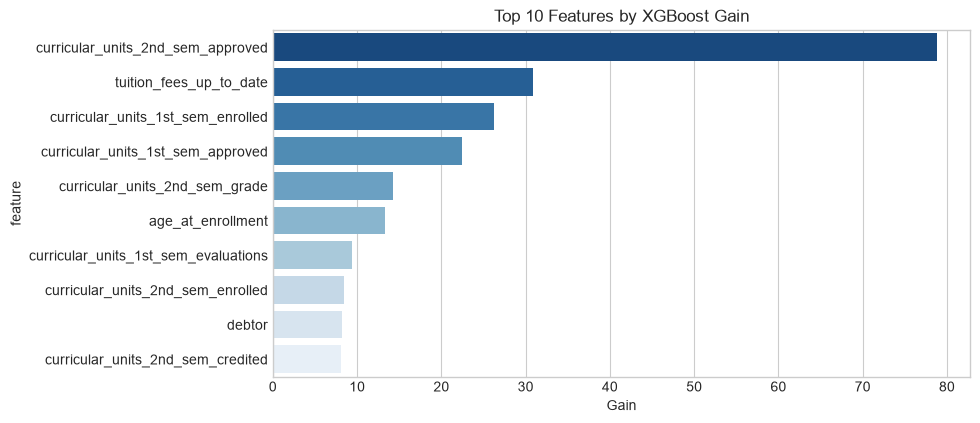

In [14]:
importance = best_xgb.get_score(importance_type='gain')
imp_df = pd.DataFrame({'feature': list(importance.keys()), 'gain': list(importance.values())})
imp_df = imp_df.sort_values(by='gain', ascending=False).head(10)

plt.figure(figsize=(9, 4.5))
sns.barplot(data=imp_df, x='gain', y='feature', palette='Blues_r')
plt.title('Top 10 Features by XGBoost Gain')
plt.xlabel('Gain')
plt.show()

## 7. Final Model Training & Test Evaluation

Now we combine train + validation (`full_train_df`) to train the final XGBoost model, and evaluate once on the held-out test set.

In [15]:
y_full_train = full_train_df['target'].values
full_train_features = full_train_df.drop(columns=['target']).reset_index(drop=True)

dv_final = DictVectorizer(sparse=False)
X_full_train = dv_final.fit_transform(full_train_features.to_dict(orient='records'))
X_test_final = dv_final.transform(test_df.to_dict(orient='records'))

dfull_train = xgb.DMatrix(X_full_train, label=y_full_train, feature_names=dv_final.get_feature_names_out().tolist())
dtest_final = xgb.DMatrix(X_test_final, label=y_test, feature_names=dv_final.get_feature_names_out().tolist())

final_model = xgb.train(xgb_params, dfull_train, num_boost_round=100)

test_proba = final_model.predict(dtest_final)
test_pred = (test_proba >= 0.5).astype(int)

print(f"Test Set ROC-AUC:  {roc_auc_score(y_test, test_proba):.4f}")
print(f"Test Set F1 Score: {f1_score(y_test, test_pred):.4f}")

Test Set ROC-AUC:  0.9335
Test Set F1 Score: 0.8053


## 8. Save the Model

Save `dv_final` and `final_model` to `model.bin` using pickle so they can be loaded by `predict.py`.

In [16]:
with open('model.bin', 'wb') as f_out:
    pickle.dump((dv_final, final_model), f_out)

print("Saved model and vectorizer to model.bin")

Saved model and vectorizer to model.bin


Test loading the model and making a sample prediction:

In [17]:
# Verify loading
with open('model.bin', 'rb') as f_in:
    loaded_dv, loaded_model = pickle.load(f_in)

sample_student = test_df.iloc[0].to_dict()
X_sample = loaded_dv.transform([sample_student])
dsample = xgb.DMatrix(X_sample, feature_names=loaded_dv.get_feature_names_out().tolist())
pred_prob = float(loaded_model.predict(dsample)[0])

print(f"Sample student dropout probability: {pred_prob:.4f}")
print(f"Prediction: {'Dropout' if pred_prob >= 0.5 else 'Retained'} (Actual: {y_test[0]})")

Sample student dropout probability: 0.0518
Prediction: Retained (Actual: 0)
